In [20]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import MemorySaver

In [21]:
load_dotenv()

True

In [22]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

In [23]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]

In [24]:
def chat_node(state: ChatState):
    #take user query from state
    messages = state['messages']
    # send to llm
    response = llm.invoke(messages)
    # response store state
    return {'messages': [response]}

In [25]:
checkpoint = MemorySaver()
graph = StateGraph(ChatState)

graph.add_node("chat_node", chat_node)

#add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

chatbot = graph.compile(checkpointer=checkpoint)


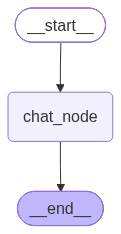

In [26]:
chatbot

In [35]:
thread_id = "1"
initial_state = {
    'messages': [HumanMessage(content='what is my name')]
}

config = {'configurable': {'thread_id': thread_id}}
response = chatbot.invoke(initial_state, config=config)
response['messages'][-1].content


'Your name is **Ronik**.'

In [36]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='hey there i am ronik ', additional_kwargs={}, response_metadata={}, id='ea1be269-12bd-4968-a47b-b9903ecf46d7'), AIMessage(content='Hey Ronik! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hey there i am ronik". They are greeting. We should respond politely, maybe ask how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 49, 'prompt_tokens': 78, 'total_tokens': 127, 'completion_time': 0.05479685, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.004406862, 'prompt_tokens_details': None, 'queue_time': 0.738142981, 'total_time': 0.059203712}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_bb6a356524', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e55c-a60a-7693-be31-f9283b005740-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 78, 'output_tokens':

In [29]:
thread_id = "1"

while True:
    user_message = input('Type here: ')

    print('User:', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break

    config = {'configurable': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)

    print('AI:', response['messages'][-1].content)

User: hey there i am ronik 
AI: Hey Ronik! 👋 How can I help you today?
User: hello brother
AI: Hey there, brother! 👋 How’s it going? What’s on your mind today?
User: what is my name
AI: You’re Ronik!
User: my thread id is 1
AI: Got it—your thread ID is **1**. How can I help you with that?
User: what is my name iwth rthread id
AI: Your name is **Ronik** and your thread ID is **1**.
User: who is thread id 1
AI: Thread ID 1 refers to the user in this conversation—i.e., you.
User: exit
